In [15]:
from autogluon.tabular import TabularPredictor
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import f1_score
import numpy as np
import pickle
import pandas as pd
from sklearn.metrics import f1_score, classification_report, confusion_matrix, balanced_accuracy_score, matthews_corrcoef, cohen_kappa_score
import seaborn as sns
import matplotlib.pyplot as plt

In [16]:
with open(r"/home/matildxi/Secretária/Documentos/Tese/anxolotl/processed_data/wesad/processed_data.pkl", 'rb') as f:
      data = pickle.load(f)

df = data['df']

In [17]:
logo = LeaveOneGroupOut()
groups = df['subject'].values
fold_f1s = []
all_preds = []
all_labels = []
all_scores = []

In [18]:
feature_cols = [c for c in df.columns if c not in ['subject', 'label']]

for fold, (train_idx, test_idx) in enumerate(logo.split(df, df['label'], groups=groups)):
    subject_id = groups[test_idx[0]]
    print(f"Fold {fold+1:2d} | Test subject: {subject_id}")

    train_df = df.iloc[train_idx][feature_cols + ['label']]
    test_df  = df.iloc[test_idx][feature_cols]
    y_test   = df.iloc[test_idx]['label'].values

    predictor = TabularPredictor(
        label='label',
        eval_metric='f1_macro',
        verbosity=0
    ).fit(
        train_df,
        time_limit=600,
        presets='best_quality'
    )

    preds = predictor.predict(test_df).values
    proba = predictor.predict_proba(test_df)[1].values
    f1 = f1_score(y_test, preds, average='macro')
    fold_f1s.append(f1)
    all_preds.extend(preds)
    all_labels.extend(y_test)
    all_scores.extend(proba)
    print(f"           Macro F1: {f1:.4f}\n")

print("=" * 50)
print(f"Macro F1 por fold: {[f'{v:.4f}' for v in fold_f1s]}")
print(f"Média: {np.mean(fold_f1s):.4f}  |  Std: {np.std(fold_f1s):.4f}")

Fold  1 | Test subject: S10
           Macro F1: 0.7251

Fold  2 | Test subject: S11
           Macro F1: 0.5451

Fold  3 | Test subject: S13
           Macro F1: 0.6845

Fold  4 | Test subject: S14
           Macro F1: 0.9790

Fold  5 | Test subject: S15
           Macro F1: 0.8292

Fold  6 | Test subject: S16
           Macro F1: 1.0000

Fold  7 | Test subject: S17
           Macro F1: 0.9000

Fold  8 | Test subject: S2
           Macro F1: 0.6019

Fold  9 | Test subject: S3
           Macro F1: 0.7426

Fold 10 | Test subject: S4
           Macro F1: 0.9232

Fold 11 | Test subject: S5
           Macro F1: 0.9813

Fold 12 | Test subject: S6
           Macro F1: 0.9160

Fold 13 | Test subject: S7
           Macro F1: 0.9332

Fold 14 | Test subject: S8
           Macro F1: 0.9822

Fold 15 | Test subject: S9
           Macro F1: 0.9525

Macro F1 por fold: ['0.7251', '0.5451', '0.6845', '0.9790', '0.8292', '1.0000', '0.9000', '0.6019', '0.7426', '0.9232', '0.9813', '0.9160', '0.9332', '0.

Estatísticas FINAIS - AutoGluon 
              precision    recall  f1-score   support

    baseline       0.92      0.86      0.89     17577
      stress       0.78      0.86      0.82      9966

    accuracy                           0.86     27543
   macro avg       0.85      0.86      0.85     27543
weighted avg       0.87      0.86      0.86     27543

Balanced Accuracy:        0.862
Macro F1 médio por fold:  0.846
Desvio Padrão F1 (LOSO):  0.144
Matthews Corr. Coef.:     0.711
Cohen's Kappa:            0.709


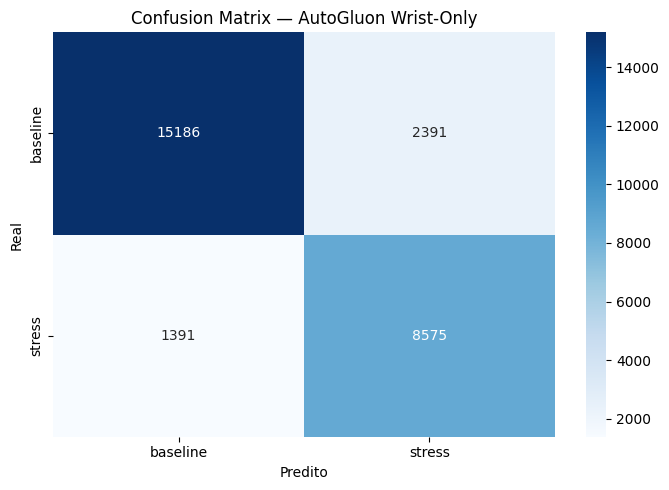

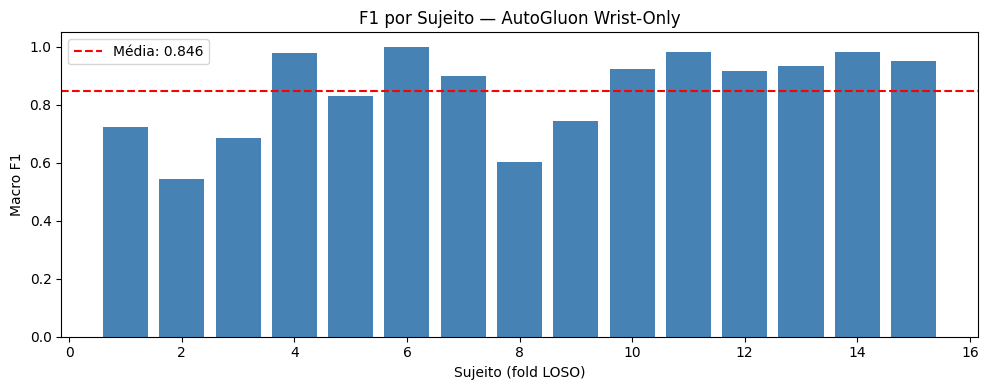

In [19]:
print("=" * 50)
print("Estatísticas FINAIS - AutoGluon ")
print("=" * 50)
print(classification_report(all_labels, all_preds,
                             target_names=['baseline', 'stress'],
                             zero_division=0))
print(f"Balanced Accuracy:        {balanced_accuracy_score(all_labels, all_preds):.3f}")
print(f"Macro F1 médio por fold:  {np.mean(fold_f1s):.3f}")
print(f"Desvio Padrão F1 (LOSO):  {np.std(fold_f1s):.3f}")
print(f"Matthews Corr. Coef.:     {matthews_corrcoef(all_labels, all_preds):.3f}")
print(f"Cohen's Kappa:            {cohen_kappa_score(all_labels, all_preds):.3f}")

# confusion matrix
plt.figure(figsize=(7, 5))
sns.heatmap(confusion_matrix(all_labels, all_preds),
            annot=True, fmt='d', cmap='Blues',
            xticklabels=['baseline', 'stress'],
            yticklabels=['baseline', 'stress'])
plt.title('Confusion Matrix — AutoGluon Wrist-Only')
plt.ylabel('Real'); plt.xlabel('Predito')
plt.tight_layout()
plt.show()

# F1 por sujeito
plt.figure(figsize=(10, 4))
plt.bar(range(1, len(fold_f1s)+1), fold_f1s, color='steelblue')
plt.axhline(np.mean(fold_f1s), color='red', linestyle='--',
            label=f'Média: {np.mean(fold_f1s):.3f}')
plt.xlabel('Sujeito (fold LOSO)')
plt.ylabel('Macro F1')
plt.title('F1 por Sujeito — AutoGluon Wrist-Only')
plt.legend()
plt.tight_layout()
plt.show()

In [20]:
# treinar AutoGluon final com todos os dados
train_df_all = df[feature_cols + ['label']]

predictor_final = TabularPredictor(
    label='label',
    eval_metric='f1_macro',
    verbosity=0,
    path='autogluon_wrist_final'
).fit(
    train_df_all,
    time_limit=300,
    presets='best_quality'
)

print("AutoGluon guardado!")

AutoGluon guardado!


In [21]:
# ROC-AUC
from sklearn.metrics import roc_auc_score
import numpy as np
_auc = roc_auc_score(np.array(all_labels), np.array(all_scores))
print(f'ROC-AUC: {_auc:.3f}')

ROC-AUC: 0.953


In [22]:
# F1 @ Youden-optimal threshold
from sklearn.metrics import roc_curve, f1_score
import numpy as np
_yt = np.array(all_labels); _ys = np.array(all_scores)
_fpr, _tpr, _thr = roc_curve(_yt, _ys)
_t_opt = float(_thr[np.argmax(_tpr - _fpr)])
_f1opt = f1_score(_yt, (_ys >= _t_opt).astype(int), average='macro', zero_division=0)
print(f'F1@opt : {_f1opt:.3f}  (threshold={_t_opt:.3f})')

F1@opt : 0.871  (threshold=0.567)
